In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx


In [7]:
data = pd.read_csv('/content/Dataset_network.csv',
                 delimiter=',',
                 header=0,
                 names=['depart', 'destination', 'distance']
                )
print(data.head(16))

            depart     destination  distance
0           Niamey          Zinder       743
1           Zinder          Agadez       367
2   Bobo-Dioulasso     Ouagadougou       333
3           Bamako  Bobo-Dioulasso       435
4      Ouagadougou           Djibo       195
5            Djibo          Niamey       408
6           Bamako           Mopti       460
7            Mopti             Gao       486
8            Mopti      Tombouctou       736
9            Mopti           Djibo       278
10             Gao          Niamey       384
11             Gao           Djibo       292
12             Gao          Niamey       384
13          Bamako     Ouagadougou       702
14     Ouagadougou          Niamey       414
15          Bamako          Niamey      1099


In [8]:
G = nx.Graph()

for _, row in data.iterrows():
    G.add_edge(row['depart'], row['destination'], weight=row['distance'])


print(f"Nombre de nœuds: {G.number_of_nodes()}")
print(f"Nombre d'arêtes: {G.number_of_edges()}")

Nombre de nœuds: 10
Nombre d'arêtes: 15


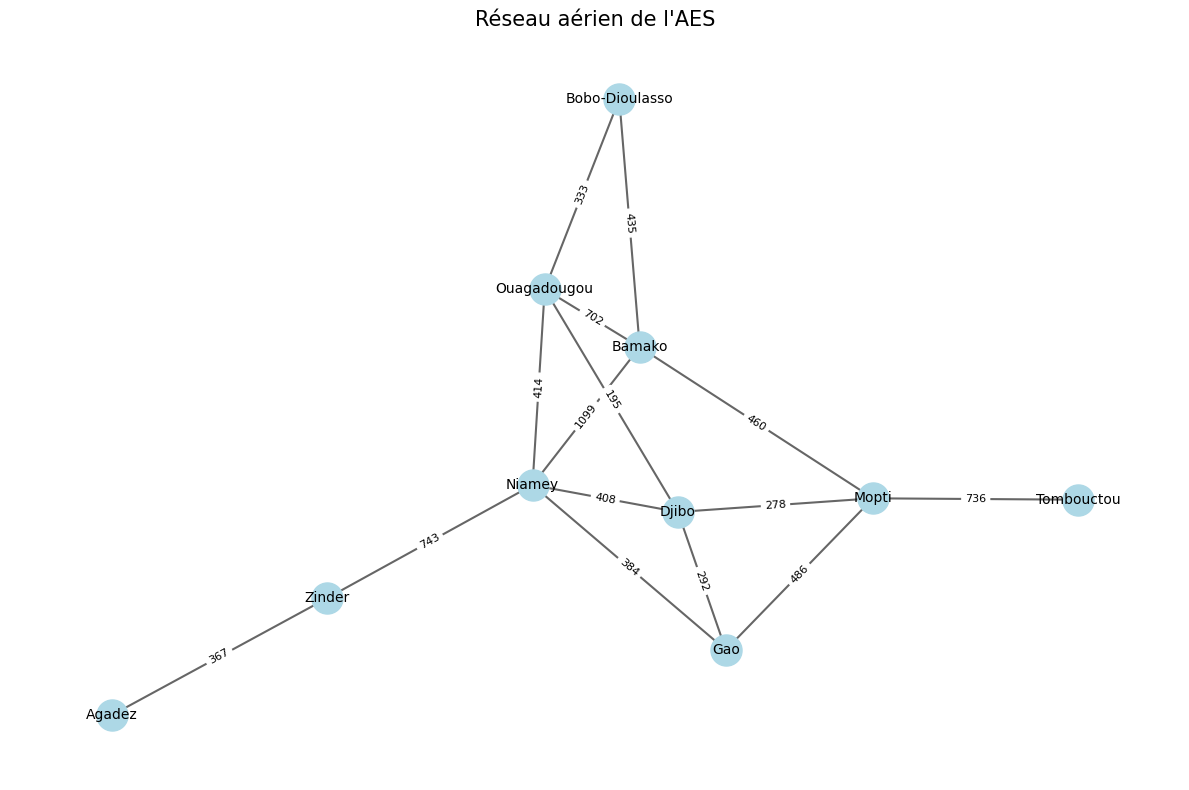

In [9]:
plt.figure(figsize=(12, 8))
pos = nx.spring_layout(G, seed=42)

nx.draw_networkx_nodes(G, pos, node_size=500, node_color='lightblue')
nx.draw_networkx_edges(G, pos, width=1.5, alpha=0.6)
nx.draw_networkx_labels(G, pos, font_size=10, font_family='sans-serif')

edge_labels = nx.get_edge_attributes(G, 'weight')
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=8)

plt.title("Réseau aérien de l'AES", size=15)
plt.axis('off')
plt.tight_layout()
plt.show()

In [11]:
distance = nx.shortest_path_length(G, source="Tombouctou", target="Bobo-Dioulasso", weight='weight')
print(f"Distance entre Tombouctou et Bobo-Dioulasso: {distance} km")

Distance entre Tombouctou et Bobo-Dioulasso: 1542 km


In [12]:
def calculate_distances(G):
    all_distances = []
    for node1 in G.nodes():
        for node2 in G.nodes():
            if node1 != node2:
                try:
                    dist = nx.shortest_path_length(G, source=node1, target=node2, weight='weight')
                    all_distances.append(dist)
                except nx.NetworkXNoPath:
                    continue

    min_dist = min(all_distances)
    max_dist = max(all_distances)
    return min_dist, max_dist

min_dist, max_dist = calculate_distances(G)
print(f"Plus courte distance: {min_dist} km")
print(f"Plus longue distance: {max_dist} km")

Plus courte distance: 195 km
Plus longue distance: 2532 km


In [13]:
degrees = dict(G.degree())
max_degree_city = max(degrees, key=degrees.get)
print(f"Ville avec le plus grand degré: {max_degree_city} (degré {degrees[max_degree_city]})")

Ville avec le plus grand degré: Niamey (degré 5)


In [14]:
proximiter = nx.closeness_centrality(G, distance='weight')
for ville, centrality in proximiter.items():
    print(f"{ville}: {centrality:.4f}")

Niamey: 0.0013
Zinder: 0.0008
Agadez: 0.0006
Bobo-Dioulasso: 0.0011
Ouagadougou: 0.0014
Bamako: 0.0009
Djibo: 0.0015
Mopti: 0.0013
Gao: 0.0012
Tombouctou: 0.0007


In [15]:
vecteur_propre = nx.eigenvector_centrality(G, max_iter=1000, weight='weight')
for ville, centrality in vecteur_propre.items():
    print(f"{ville}: {centrality:.4f}")

Niamey: 0.5601
Zinder: 0.2215
Agadez: 0.0417
Bobo-Dioulasso: 0.1862
Ouagadougou: 0.3710
Bamako: 0.5497
Djibo: 0.2206
Mopti: 0.2479
Gao: 0.2053
Tombouctou: 0.0936


Niamey (0.5601) et Bamako (0.5497)  sont les villes les plus influentes dans le reseau, étant connectées à d'autres villes importantes; donc la mise en place une compagnie aérienne reliant ces villes est plus impactantes.

Ouagadougou (0.3710) est une ville secondaire et a une influence notable sur le reseau.



In [16]:
intermédiarité = nx.betweenness_centrality(G, weight='weight')
for ville, centrality in intermédiarité.items():
    print(f"{ville}: {centrality:.4f}")

Niamey: 0.3889
Zinder: 0.2222
Agadez: 0.0000
Bobo-Dioulasso: 0.0000
Ouagadougou: 0.1944
Bamako: 0.0000
Djibo: 0.3333
Mopti: 0.2778
Gao: 0.0000
Tombouctou: 0.0000


Niamey(0.3889) a la valeur la plus élevée du reseau ; la plupart des trajets dépendent de Niamey .


Une pertubation dans la ville impacterait fortement le reseau.

Mopti(0.2778) et Djibo (0.3333) sont des points important dans le reseau,car sont des relais stratégiques dans la connexion a plusieurs autres villes.

In [17]:
pagerank = nx.pagerank(G, alpha=0.85, weight='weight')
for city, rank in pagerank.items():
    print(f"{city}: {rank:.4f}")

Niamey: 0.1921
Zinder: 0.0888
Agadez: 0.0399
Bobo-Dioulasso: 0.0560
Ouagadougou: 0.1059
Bamako: 0.1658
Djibo: 0.0808
Mopti: 0.1327
Gao: 0.0806
Tombouctou: 0.0574


Niamey (0.1921) est la ville la plus importante du reseau car elle a le plus de connexions et est reliées à d’autres villes importants.

Bamako (0.1658) est la seconde ville la plus importante du reseau .

Une perturbation sur l’une de ces villes affecterait tout le réseau.

In [18]:
density = nx.density(G)
print(f"Densité du réseau: {density:.4f}")

Densité du réseau: 0.3333
